# 11 · Time Evolution and $g^{(2)}(\tau)$

**Covers:** the Schrödinger equation with `sesolve`, open systems with `mesolve` and collapse operators, and the delay-dependent correlation $g^{(2)}(\tau)$ for three kinds of light.
**Photonics thread:** a directional coupler is coupled-mode theory written as a Hamiltonian; a ring's Q sets the photon lifetime; a Hanbury Brown–Twiss measurement of $g^{(2)}(\tau)$ is the everyday lab fingerprint of a light source.

In [1]:
import numpy as np
import qutip as qt

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

## 1. A photon travelling through a directional coupler

**Plain words:** the Hamiltonian $H$ is the rule of motion, $i\,d|\psi\rangle/dz = H|\psi\rangle$. For two coupled waveguides

$$H = \kappa\,(a^\dagger b + a b^\dagger),\qquad P(\text{photon stays in } a) = \cos^2(\kappa z)$$

the classical coupled-mode result, now for a single photon. Two photons, one per input, reach the HOM dip at the 50:50 length $z = \pi/4\kappa$.

**Gap:** no loss and no wavelength dependence of κ, so the 50:50 point is exact at one wavelength only.

In [2]:
N = 3
a = qt.tensor(qt.destroy(N), qt.qeye(N))
b = qt.tensor(qt.qeye(N), qt.destroy(N))
kappa = 1.0                                        # coupling per unit length
H = kappa * (a.dag() * b + a * b.dag())
psi0 = qt.tensor(qt.basis(N, 1), qt.basis(N, 0))   # photon starts in waveguide a
z = np.linspace(0, np.pi, 9)
res = qt.sesolve(H, psi0, z, e_ops=[a.dag() * a, b.dag() * b])
for zi, na in list(zip(z, res.expect[0]))[::2]:
    check(f"P(stay) at z = {zi:.3f}", na, np.cos(kappa * zi) ** 2)

psi11 = qt.tensor(qt.basis(N, 1), qt.basis(N, 1))
res2 = qt.sesolve(H, psi11, [0, np.pi / 4])
check("HOM dip at the 50:50 length: P(1,1)", abs(psi11.dag() * res2.states[-1]) ** 2, 0.0)

PASS  P(stay) at z = 0.000: simulation = 1.0000, theory = 1.0000
PASS  P(stay) at z = 0.785: simulation = 0.5000, theory = 0.5000
PASS  P(stay) at z = 1.571: simulation = 0.0000, theory = 0.0000
PASS  P(stay) at z = 2.356: simulation = 0.5000, theory = 0.5000
PASS  P(stay) at z = 3.142: simulation = 1.0000, theory = 1.0000
PASS  HOM dip at the 50:50 length: P(1,1): simulation = 0.0000, theory = 0.0000


## 2. A photon leaking out of a ring

**Plain words:** a ring holds a photon like a leaky bucket holds water. A collapse operator $\sqrt{\gamma}\,a$ says "a photon may escape at rate γ":

$$\langle n\rangle(t) = e^{-\gamma t},\qquad \tau = 1/\gamma = Q/\omega,\qquad \text{linewidth} = \gamma/2\pi$$

With the loaded Q of the silicon ring in Ma et al. ([arXiv:1710.01001](https://arxiv.org/abs/1710.01001)), Q = 92,000, this gives the lifetime (~76 ps) and linewidth (~2.1 GHz) stated in that paper.

In [3]:
Nc = 5
c_op = qt.destroy(Nc)
lam = 1550e-9
omega = 2 * np.pi * 2.998e8 / lam
Q = 9.2e4
tau = Q / omega
gamma = 1 / tau
check("photon lifetime (ps) vs paper ~76", tau * 1e12, 76, tol=1)
check("linewidth (GHz) vs paper ~2.1", gamma / (2 * np.pi) / 1e9, 2.1, tol=0.05)

t = np.linspace(0, 3 * tau, 4)
res3 = qt.mesolve(0 * c_op.dag() * c_op, qt.basis(Nc, 1), t, c_ops=[np.sqrt(gamma) * c_op], e_ops=[c_op.dag() * c_op])
for ti, ni in zip(t, res3.expect[0]):
    check(f"<n> after {ti / tau:.0f} lifetimes", ni, np.exp(-ti / tau))

PASS  photon lifetime (ps) vs paper ~76: simulation = 75.7021, theory = 76.0000
PASS  linewidth (GHz) vs paper ~2.1: simulation = 2.1024, theory = 2.1000
PASS  <n> after 0 lifetimes: simulation = 1.0000, theory = 1.0000
PASS  <n> after 1 lifetimes: simulation = 0.3679, theory = 0.3679
PASS  <n> after 2 lifetimes: simulation = 0.1353, theory = 0.1353
PASS  <n> after 3 lifetimes: simulation = 0.0498, theory = 0.0498


## 3. $g^{(2)}(\tau)$: three fingerprints

$g^{(2)}(\tau)$ asks: if a photon arrives now, how likely is another one τ later, compared with chance?

| Light | $g^{(2)}(0)$ | Shape |
|---|---|---|
| Laser | 1 | flat: arrivals independent |
| Thermal (one arm of a pair source) | 2 | $1 + e^{-\gamma\tau}$: bunching |
| Single emitter (weak drive) | 0 | $(1 - e^{-\gamma\tau/2})^2$: antibunching |

The width of the curve is the coherence time or the emitter lifetime.

**Numerical note:** for the weakly driven emitter the signal is tiny, and default solver tolerances leave a ~1 % error. Tightening the tolerances removes it: when the signal is small, check the solver's precision, not only the physics.

In [4]:
taus = np.linspace(0, 8, 81)                       # in units of 1/gamma
g = 1.0

Nl = 15
al = qt.destroy(Nl)
g2_laser, _ = qt.coherence_function_g2(1.0 * (al + al.dag()), None, taus, [np.sqrt(g) * al], al)
check("laser g2(0)", g2_laser[0], 1.0)
check("laser g2(4/gamma)", g2_laser[40], 1.0)

nth = 0.5
c_th = [np.sqrt(g * (1 + nth)) * al, np.sqrt(g * nth) * al.dag()]
g2_th, _ = qt.coherence_function_g2(0 * al.dag() * al, None, taus, c_th, al)
for i in [0, 10, 20, 40]:
    check(f"thermal g2 at tau = {taus[i]:.0f}", g2_th[i], 1 + np.exp(-g * taus[i]))

sm = qt.destroy(2)
Om = 0.02
tight = {"atol": 1e-12, "rtol": 1e-10}
g2_at, _ = qt.coherence_function_g2(Om / 2 * (sm + sm.dag()), None, taus, [np.sqrt(g) * sm], sm, options=tight)
for i in [0, 10, 20, 40, 80]:
    check(f"emitter g2 at tau = {taus[i]:.0f}", g2_at[i], (1 - np.exp(-g * taus[i] / 2)) ** 2)

PASS  laser g2(0): simulation = 0.9996, theory = 1.0000
PASS  laser g2(4/gamma): simulation = 0.9999, theory = 1.0000
PASS  thermal g2 at tau = 0: simulation = 1.9999, theory = 2.0000
PASS  thermal g2 at tau = 1: simulation = 1.3678, theory = 1.3679
PASS  thermal g2 at tau = 2: simulation = 1.1353, theory = 1.1353
PASS  thermal g2 at tau = 4: simulation = 1.0183, theory = 1.0183
PASS  emitter g2 at tau = 0: simulation = 0.0000, theory = 0.0000
PASS  emitter g2 at tau = 1: simulation = 0.1549, theory = 0.1548
PASS  emitter g2 at tau = 2: simulation = 0.3999, theory = 0.3996
PASS  emitter g2 at tau = 4: simulation = 0.7480, theory = 0.7476
PASS  emitter g2 at tau = 8: simulation = 0.9639, theory = 0.9637


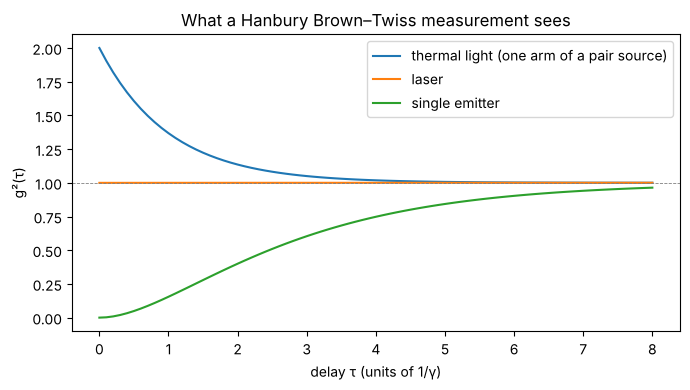

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.plot(taus, np.real(g2_th), label="thermal light (one arm of a pair source)")
plt.plot(taus, np.real(g2_laser), label="laser")
plt.plot(taus, np.real(g2_at), label="single emitter")
plt.axhline(1, color="gray", lw=0.6, ls="--")
plt.xlabel("delay τ (units of 1/γ)"); plt.ylabel("g²(τ)")
plt.title("What a Hanbury Brown–Twiss measurement sees")
plt.legend(); plt.tight_layout(); plt.show()

## Validation summary

Every `check` above compared a QuTiP result with its analytic formula.

In [6]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

23 of 23 checks passed
